In [2]:
#1. Significant earthquakes since 2150 B.C.

In [ ]:
# 导入函数模组

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
%matplotlib inline

In [3]:
# 读取tsv文件
Sig_Eqs = pd.read_csv(r"D:\huanjingbianceng\2cizuoye\Sig_Eqs.tsv", sep='\t')
Sig_Eqs.info(5)
Sig_Eqs.head(5)

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

,Search Parameters,Id,Year,Mo,Dy,Hr,Mn,Sec,Tsu,Vol,...,Total Missing,Total Missing Description,Total Injuries,Total Injuries Description,Total Damage ($Mil),Total Damage Description,Total Houses Destroyed,Total Houses Destroyed Description,Total Houses Damaged,Total Houses Damaged Description
0,[],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.0,-2150.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,-2000.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,3.0,-2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN
4,NaN,5877.0,-1610.0,NaN,NaN,NaN,NaN,NaN,3.0,1351.0,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN


In [4]:
# 1.1 按国家分组，计算死亡总数，na忽略缺失
death_by_country = Sig_Eqs.groupby('Country')['Deaths'].sum()
# 降序排列
death_by_country = death_by_country.sort_values(ascending=False)
# 打印前20名
print("====Top 20 countries by total earthquake deaths====")
print(death_by_country.head(20))


====Top 20 countries by total earthquake deaths====
Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014438.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


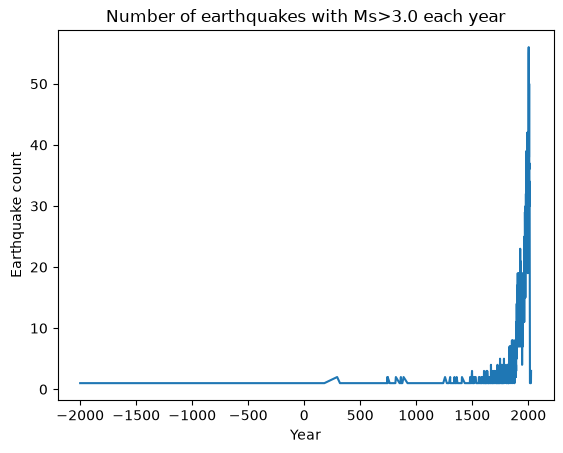

In [5]:
# 1.2 筛选 Ms >3.0 的地震
eq_ms3 = Sig_Eqs.loc[Sig_Eqs['Ms'] > 3.0]
# 按年份分组，统计每年地震数量
eq_year_count = eq_ms3.groupby('Year').size()
# 绘图
eq_year_count.plot()
plt.title("Number of earthquakes with Ms>3.0 each year")
plt.xlabel("Year")
plt.ylabel("Earthquake count")
plt.show()

In [11]:
# 自定义函数：输入国家名，返回该国地震总次数 + 历史最大震级地震的年份和地点
def CountEq_LargestEq(country_name):
    # loc筛选出目标国家的所有地震记录
    country_data = Sig_Eqs.loc[Sig_Eqs["Country"] == country_name] 
    # 计算该国地震总数量
    total_eq = len(country_data)
    # 筛选出Ms震级不为空的有效记录，过滤NaN缺失值
    valid_ms = country_data.loc[country_data["Ms"].notna()]
    # 判断：如果这个国家没有任何有效震级数据
    if len(valid_ms) == 0:
        largest_info = "No valid magnitude data"
    else:
        # 5. 在有效数据中找到Ms震级最大的那一行
        max_row = valid_ms.loc[valid_ms["Ms"].idxmax()]
        # 6. 拼接最大地震的年份和地点
        largest_info = f"Year: {max_row['Year']}, Location: {max_row['Location Name']}"
    # 返回字典格式结果
    return {"Country": country_name, "Total_EQ": total_eq, "Largest_EQ": largest_info}
#  获取数据集中所有不重复的国家名称
all_country_list = Sig_Eqs["Country"].unique()
#  创建空列表，用来存放每个国家的计算结果
result_list = []
#  for循环遍历每个国家，调用函数计算并保存结果
for country in all_country_list:
    res = CountEq_LargestEq(country)
    result_list.append(res)
#  将结果列表转换为DataFrame表格
result_df = pd.DataFrame(result_list)
#  按照地震总数Total_EQ降序排序
result_df = result_df.sort_values("Total_EQ", ascending=False)
result_df

,Country,Total_EQ,Largest_EQ
15,CHINA,626,"Year: 1920.0, Location: CHINA: GANSU PROVINCE..."
34,JAPAN,429,"Year: 869.0, Location: JAPAN: SANRIKU"
74,INDONESIA,427,"Year: 2004.0, Location: INDONESIA: SUMATRA: ..."
8,IRAN,385,"Year: 856.0, Location: IRAN: DAMGHAN, QUMIS"
10,TURKEY,359,"Year: 1939.0, Location: TURKEY: ERZINCAN"
...,...,...,...
155,BURUNDI,1,No valid magnitude data
161,ZAMBIA,1,No valid magnitude data
160,MADAGASCAR,1,No valid magnitude data
162,COMOROS,1,No valid magnitude data


In [13]:
#2. Air temperature in Shenzhen 1998-2022

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [15]:
df = pd.read_csv(r"D:\huanjingbianceng\2cizuoye\Baoan_Weather_1998_2022.csv", low_memory=False)
# 看前5行数据
print(df.head(5))
# 查看所有列的名字
print(df.columns)

       STATION                 DATE  SOURCE REPORT_TYPE CALL_SIGN  \
0  59493099999  1998-01-01T00:00:00       4       SY-MT     ZGSZ    
1  59493099999  1998-01-01T01:00:00       4       FM-15     ZGSZ    
2  59493099999  1998-01-01T02:00:00       4       FM-15     ZGSZ    
3  59493099999  1998-01-01T03:00:00       4       SY-MT     ZGSZ    
4  59493099999  1998-01-01T04:00:00       4       FM-15     ZGSZ    

  QUALITY_CONTROL          AA1  AA2  AA3    AG1  ... REPORT_TYPE.1  SA1  \
0            V020  06,0000,9,1  NaN  NaN  0,000  ...         SY-MT  NaN   
1            V020          NaN  NaN  NaN  0,999  ...         FM-15  NaN   
2            V020          NaN  NaN  NaN  0,999  ...         FM-15  NaN   
3            V020          NaN  NaN  NaN  0,000  ...         SY-MT  NaN   
4            V020          NaN  NaN  NaN  0,999  ...         FM-15  NaN   

       SLP SOURCE.1      TMP  UA1  UG1           VIS WG1             WND  
0  10184,1        4  +0186,1  NaN  NaN  008000,1,N,1 NaN  0

In [22]:
# TMP格式是 "温度,标记"，先分割取出逗号左边的温度字符串
df["TMP_only"] = df["TMP"].str.split(',').str[0]
# 筛选：TMP不等于"9999,9"
df_valid = df.loc[df["TMP_only"] != "9999"].copy()
# 转为数字，errors='coerce'遇到脏字符自动变成NaN
df_valid["TMP_num"] = pd.to_numeric(df_valid["TMP_only"], errors='coerce')
# 删除转换失败的空行
df_valid = df_valid.dropna(subset=["TMP_num"])
# 真实气温 = 数值 /10
df_valid["Temp_C"] = df_valid["TMP_num"] / 10
# 打印结果检查
print(df_valid[["TMP", "TMP_only", "TMP_num", "Temp_C"]].head(5))

       TMP TMP_only  TMP_num  Temp_C
0  +0186,1    +0186      186    18.6
1  +0220,1    +0220      220    22.0
2  +0240,1    +0240      240    24.0
3  +0221,1    +0221      221    22.1
4  +0240,1    +0240      240    24.0


In [24]:
# 将DATE字符串转为pandas时间格式
df_valid["DATE"] = pd.to_datetime(df_valid["DATE"])
# 从时间中提取出 年、月
df_valid["year"] = df_valid["DATE"].dt.year
df_valid["month"] = df_valid["DATE"].dt.month
# 打印检查结果
print(df_valid[["DATE", "year", "month", "Temp_C"]].head(5))

                 DATE  year  month  Temp_C
0 1998-01-01 00:00:00  1998      1    18.6
1 1998-01-01 01:00:00  1998      1    22.0
2 1998-01-01 02:00:00  1998      1    24.0
3 1998-01-01 03:00:00  1998      1    22.1
4 1998-01-01 04:00:00  1998      1    24.0


In [25]:
# groupby 按year、month分组，对Temp_C求平均值
monthly_temp = df_valid.groupby(["year", "month"])["Temp_C"].mean().reset_index()
# 构造绘图用时间：把每年每月的1号作为代表时间点
monthly_temp["plot_time"] = pd.to_datetime({
    "year": monthly_temp["year"],
    "month": monthly_temp["month"],
    "day": 1
})
# 查看前五行月平均气温结果
print(monthly_temp.head(5))

   year  month     Temp_C  plot_time
0  1998      1  15.233447 1998-01-01
1  1998      2  18.581944 1998-02-01
2  1998      3  19.971246 1998-03-01
3  1998      4  29.891866 1998-04-01
4  1998      5  27.098454 1998-05-01


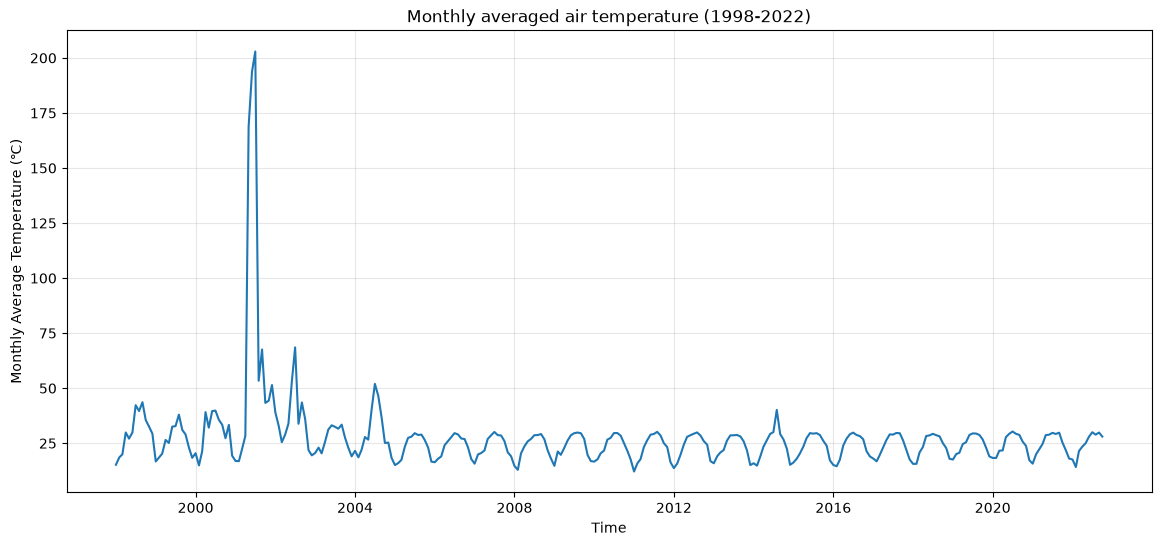

In [27]:
plt.figure(figsize=(14,6))
# x轴：构造好的时间plot_time，y轴：月平均气温Temp_C
plt.plot(monthly_temp["plot_time"], monthly_temp["Temp_C"])
plt.title("Monthly averaged air temperature (1998‑2022)")
plt.xlabel("Time")
plt.ylabel("Monthly Average Temperature (℃)")
plt.grid(alpha=0.3)
plt.show()

In [28]:
print("数据开始时间：", monthly_temp["plot_time"].min())
print("数据结束时间：", monthly_temp["plot_time"].max())
print("总共有多少个月：", len(monthly_temp))

数据开始时间： 1998-01-01 00:00:00
数据结束时间： 2022-10-01 00:00:00
总共有多少个月： 298


In [ ]:
#3. Global collection of hurricanes

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
file_path = r"D:\huanjingbianceng\2cizuoye\ibtracs.ALL.list.v04r00\ibtracs.ALL.list.v04r00.csv"
df = pd.read_csv(file_path,
                 usecols=range(17),
                 skiprows=[1],
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])
# 查看前5行，验证读取成功
df.head(5)

C:\Users\龚弘\AppData\Local\Temp\ipykernel_26880\331032641.py:5: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path,


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,,,,main,43,0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,,,,main,0,0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,,,,main,0,0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,,,,main,0,0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,,,,main,0,0,__________O___


In [30]:
#  3.1 
# 按SID分组，取每个气旋最大WMO_WIND，取出前10
storm_max_wind = df.groupby(['SID','NAME'])['WMO_WIND'].max().reset_index()
top10_storm = storm_max_wind.sort_values('WMO_WIND', ascending=False).head(10)
print("====Top 10 storms by maximum WMO_Wind====")
print(top10_storm)

====Top 10 storms by maximum WMO_Wind====
               SID     NAME WMO_WIND
119  1950224N17305     ABLE       95
122  1950234N11334  CHARLIE       95
125  1950244N20277     EASY       95
127  1950251N16319      FOX       95
131  1950270N25309   GEORGE       95
154  1951224N12316  CHARLIE       95
157  1951244N13328     EASY       95
158  1951246N13340      FOX       95
185  1952244N15306    BAKER       95
189  1952268N20291  CHARLIE       95


In [31]:
# 3.2 
top20_storm = storm_max_wind.sort_values('WMO_WIND', ascending=False).head(20)
print("====Top 20 strongest storms, WMO_WIND====")
print(top20_storm[['SID','NAME','WMO_WIND']])

====Top 20 strongest storms, WMO_WIND====
               SID      NAME WMO_WIND
119  1950224N17305      ABLE       95
122  1950234N11334   CHARLIE       95
125  1950244N20277      EASY       95
127  1950251N16319       FOX       95
131  1950270N25309    GEORGE       95
154  1951224N12316   CHARLIE       95
157  1951244N13328      EASY       95
158  1951246N13340       FOX       95
185  1952244N15306     BAKER       95
189  1952268N20291   CHARLIE       95
197  1952295N11282       FOX       95
221  1953240N14340     CAROL       95
224  1953258N19296      EDNA       95
226  1953267N15282  FLORENCE       95
237  1954176N22266     ALICE       95
244  1954238N24285     CAROL       95
248  1954248N20295      EDNA       95
254  1954278N12302     HAZEL       95
272  1955215N15320    CONNIE       95
279  1955253N14319      IONE       95


In [32]:
#3.3 
basin_counts = df['BASIN'].value_counts()
print("====Data points count by BASIN====")
print(basin_counts)

====Data points count by BASIN====
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64


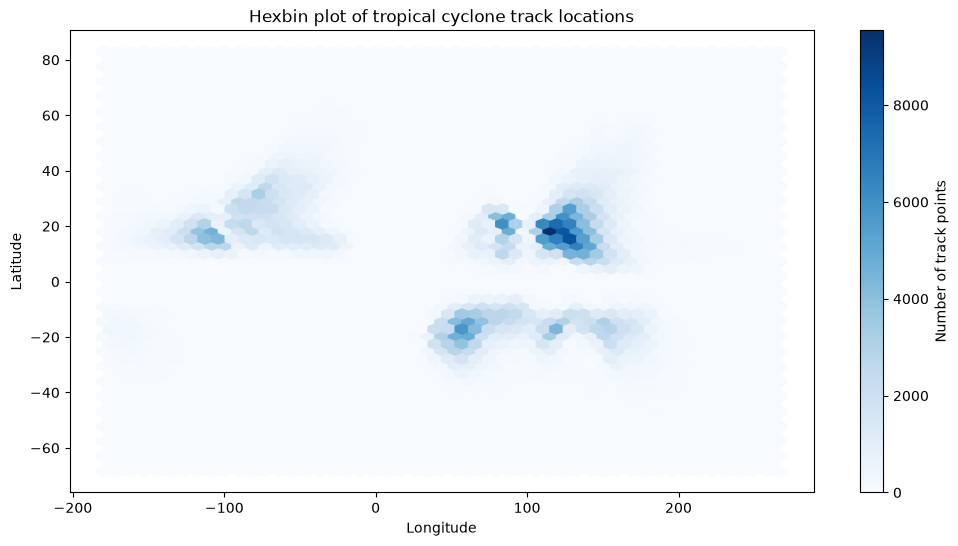

In [33]:
# 3.4 
plt.figure(figsize=(12,6))
plt.hexbin(df['LON'], df['LAT'], gridsize=50, cmap='Blues')
plt.colorbar(label="Number of track points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Hexbin plot of tropical cyclone track locations")
plt.show()

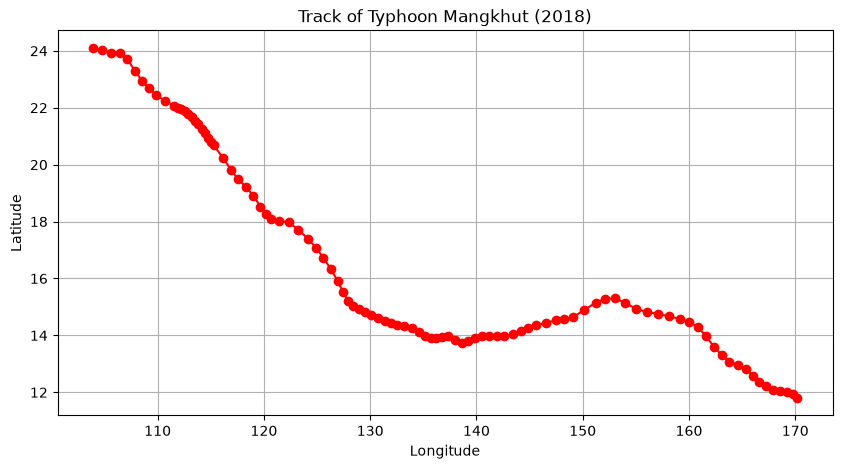

Typhoon Mangkhut (2018) track data preview:
                  ISO_TIME      LAT      LON WMO_WIND
683019 2018-09-06 12:00:00  11.8000  170.200         
683020 2018-09-06 15:00:00  11.9275  169.745         
683021 2018-09-06 18:00:00  12.0000  169.225         
683022 2018-09-06 21:00:00  12.0302  168.564         
683023 2018-09-07 00:00:00  12.0875  167.875         
...                    ...      ...      ...      ...
683113 2018-09-17 06:00:00  23.7000  107.150         
683114 2018-09-17 09:00:00  23.9355  106.434         
683115 2018-09-17 12:00:00  23.9400  105.600         
683116 2018-09-17 15:00:00  24.0212  104.778         
683117 2018-09-17 18:00:00  24.1000  103.900         

[99 rows x 4 columns]


In [34]:
# 3.5 
# Mangkhut 山竹 2018，NAME == MANGKHUT，SEASON=2018
mangkhut = df[(df['NAME']=="MANGKHUT") & (df['SEASON']==2018)]
plt.figure(figsize=(10,5))
plt.plot(mangkhut['LON'], mangkhut['LAT'],'o-',color='red')
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Track of Typhoon Mangkhut (2018)")
plt.grid(True)
plt.show()
print("Typhoon Mangkhut (2018) track data preview:")
print(mangkhut[['ISO_TIME','LAT','LON','WMO_WIND']])

In [35]:
# 3.6 
# SEASON >=1970 ；BASIN in ["WP","EP"]
df_filter = df[(df['SEASON'] >=1970) & (df['BASIN'].isin(["WP","EP"]))].copy()
print(f"Filtered dataset rows (>=1970, WP & EP basins): {len(df_filter)}")
print(df_filter[['SEASON','BASIN','NAME','ISO_TIME']].head())

Filtered dataset rows (>=1970, WP & EP basins): 176352
        SEASON BASIN   NAME            ISO_TIME
350394    1970    WP  NANCY 1970-02-19 00:00:00
350395    1970    WP  NANCY 1970-02-19 03:00:00
350396    1970    WP  NANCY 1970-02-19 06:00:00
350397    1970    WP  NANCY 1970-02-19 09:00:00
350398    1970    WP  NANCY 1970-02-19 12:00:00


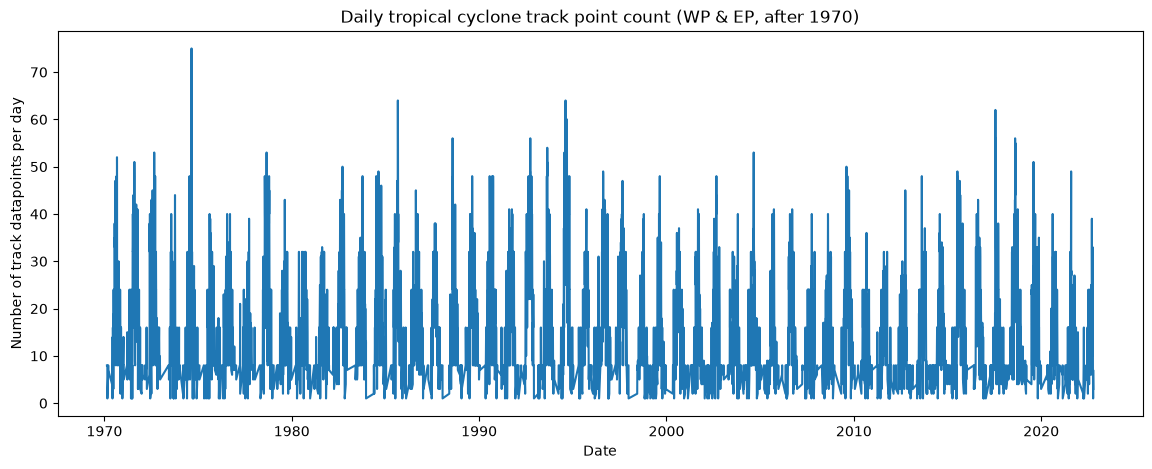

In [36]:
# 3.7 
# 提取日期（去掉时刻，只保留年月日）
df_filter['date'] = df_filter['ISO_TIME'].dt.date
daily_count = df_filter.groupby('date').size()
plt.figure(figsize=(14,5))
daily_count.plot()
plt.xlabel("Date")
plt.ylabel("Number of track datapoints per day")
plt.title("Daily tropical cyclone track point count (WP & EP, after 1970)")
plt.show()

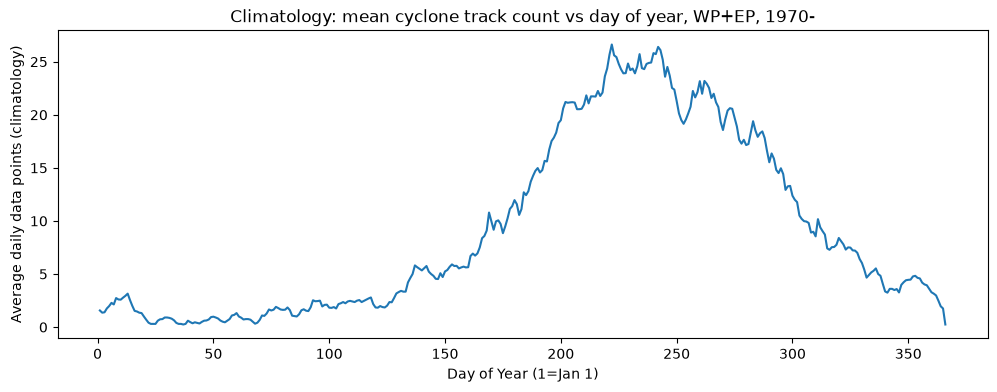

====Climatology (day of year average count)====
day_of_year
1     1.566038
2     1.358491
3     1.396226
4     1.754717
5     1.981132
6     2.283019
7     2.132075
8     2.735849
9     2.603774
10    2.584906
dtype: float64


In [37]:
# 3.8 
df_filter['day_of_year'] = df_filter['ISO_TIME'].dt.dayofyear
# 按一年中第几天分组，求多年平均（气候态climatology）
climatology = df_filter.groupby('day_of_year').size()
# 求平均：每个day_of_year的平均每日样本数量
# 先按dayofyear统计总点数，除以年份数量
num_years = df_filter['SEASON'].nunique()
climatology_mean = climatology / num_years
plt.figure(figsize=(12,4))
climatology_mean.plot()
plt.xlabel("Day of Year (1=Jan 1)")
plt.ylabel("Average daily data points (climatology)")
plt.title("Climatology: mean cyclone track count vs day of year, WP+EP, 1970-")
plt.show()
print("====Climatology (day of year average count)====")
print(climatology_mean.head(10))

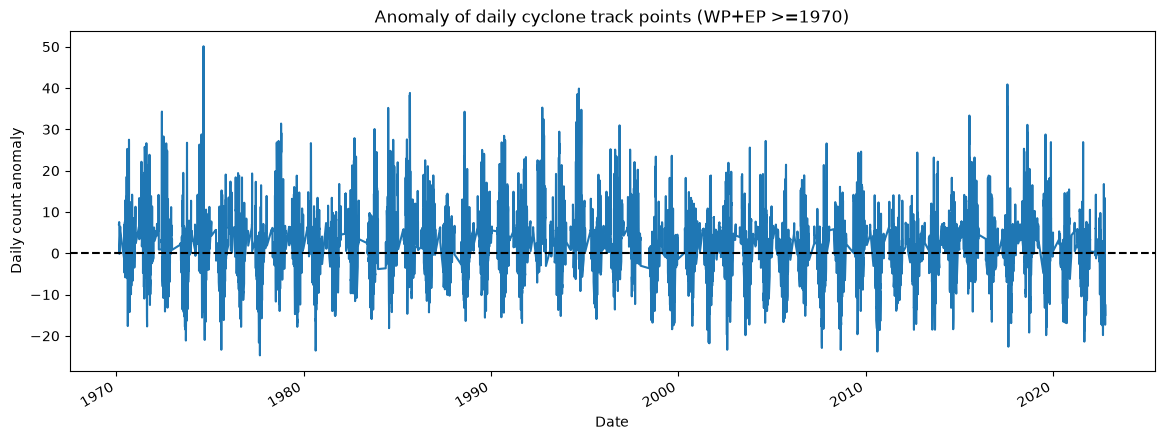

====Daily Anomaly preview====
            day_of_year  daily_points  clim_mean   anomaly
date                                                      
1970-02-19           50             8   0.981132  7.018868
1970-02-20           51             8   0.905660  7.094340
1970-02-21           52             8   0.811321  7.188679
1970-02-22           53             8   0.622642  7.377358
1970-02-23           54             8   0.509434  7.490566


In [38]:
#3.9 
# 第一步：计算每日样本数量
daily_count_df = df_filter.groupby(['date','day_of_year']).size().reset_index(name='daily_points')
# 把气候态平均合并进去
daily_count_df = daily_count_df.merge(climatology_mean.reset_index(), on="day_of_year")
daily_count_df.rename(columns={0:'clim_mean'},inplace=True)
# anomaly = 当日值 - 气候态平均值
daily_count_df['anomaly'] = daily_count_df['daily_points'] - daily_count_df['clim_mean']
# 设置时间索引，方便resample
daily_count_df['date'] = pd.to_datetime(daily_count_df['date'])
daily_count_df = daily_count_df.set_index('date')
plt.figure(figsize=(14,5))
daily_count_df['anomaly'].plot()
plt.axhline(y=0,color='k',linestyle='--')
plt.xlabel("Date")
plt.ylabel("Daily count anomaly")
plt.title("Anomaly of daily cyclone track points (WP+EP >=1970)")
plt.show()
print("====Daily Anomaly preview====")
print(daily_count_df[['day_of_year','daily_points','clim_mean','anomaly']].head())

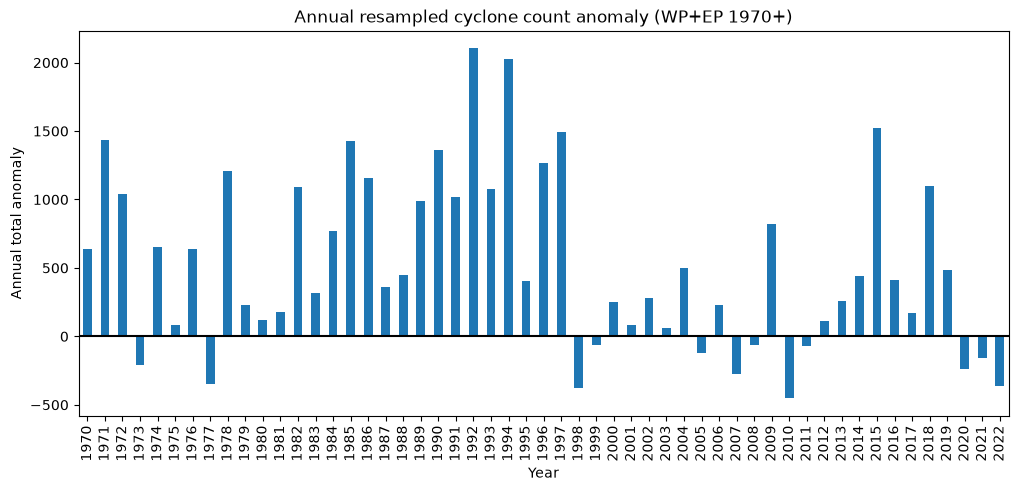

====Annual Anomaly====
date
1970     635.811321
1971    1431.735849
1972    1039.245283
1973    -208.094340
1974     656.603774
1975      83.150943
1976     638.433962
1977    -348.377358
1978    1210.547170
1979     230.415094
1980     119.528302
1981     180.962264
1982    1094.358491
1983     313.471698
1984     772.000000
1985    1423.905660
1986    1159.452830
1987     360.528302
1988     450.207547
1989     986.301887
1990    1361.150943
1991    1015.018868
1992    2104.415094
1993    1074.566038
1994    2029.641509
1995     402.735849
1996    1265.660377
1997    1494.396226
1998    -374.641509
1999     -66.622642
2000     254.018868
2001      86.377358
2002     283.981132
2003      57.698113
2004     500.226415
2005    -120.396226
2006     232.830189
2007    -271.603774
2008     -63.415094
2009     819.113208
2010    -452.679245
2011     -68.716981
2012     113.981132
2013     254.943396
2014     443.113208
2015    1523.433962
2016     410.622642
2017     172.490566
2018    1099

In [42]:
# 3.10 
annual_anomaly = daily_count_df['anomaly'].resample('YE').sum()
# 将时间索引转为单纯年份数字，画bar图不再报错
annual_anomaly.index = annual_anomaly.index.year
plt.figure(figsize=(12,5))
annual_anomaly.plot(kind='bar')
plt.axhline(y=0,color='black')
plt.xlabel("Year")
plt.ylabel("Annual total anomaly")
plt.title("Annual resampled cyclone count anomaly (WP+EP 1970+)")
plt.show()
print("====Annual Anomaly====")
print(annual_anomaly)

In [43]:
#4. Explore a data set-Global Historical Climatology Network - Daily -GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT, IL US

In [44]:
import pandas as pd
import matplotlib.pyplot as plt
# 读取本地csv文件
df = pd.read_csv(r"D:\huanjingbianceng\2cizuoye\USW00014842.csv")
# 看一下前5行和列名
print(df.head())
print(df.columns)

C:\Users\龚弘\AppData\Local\Temp\ipykernel_26880\3770765306.py:4: DtypeWarning: Columns (0: ACMH_ATTRIBUTES, 1: ACSH_ATTRIBUTES, 2: ADPT_ATTRIBUTES, 3: ASLP_ATTRIBUTES, 4: ASTP_ATTRIBUTES, 5: AWBT_ATTRIBUTES, 6: AWND_ATTRIBUTES, 7: FMTM_ATTRIBUTES, 8: FRGB_ATTRIBUTES, 9: FRGT_ATTRIBUTES, 10: FRTH_ATTRIBUTES, 11: GAHT_ATTRIBUTES, 12: PSUN_ATTRIBUTES, 13: RHAV_ATTRIBUTES, 14: RHMN_ATTRIBUTES, 15: RHMX_ATTRIBUTES, 16: TAVG_ATTRIBUTES, 17: TSUN_ATTRIBUTES, 18: WDF1_ATTRIBUTES, 19: WDF2_ATTRIBUTES, 20: WDF5_ATTRIBUTES, 21: WDFG_ATTRIBUTES, 22: WDFM_ATTRIBUTES, 23: WSF1_ATTRIBUTES, 24: WSF2_ATTRIBUTES, 25: WSF5_ATTRIBUTES, 26: WSFG_ATTRIBUTES, 27: WSFM_ATTRIBUTES, 28: WT10_ATTRIBUTES, 29: WT11_ATTRIBUTES, 30: WT13_ATTRIBUTES, 31: WT14_ATTRIBUTES, 32: WT15_ATTRIBUTES, 33: WT17_ATTRIBUTES, 34: WT19_ATTRIBUTES, 35: WT21_ATTRIBUTES, 36: WT22_ATTRIBUTES, 37: WV03_ATTRIBUTES) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"D:\huanjingbianceng\2cizuoye\U

       STATION        DATE  LATITUDE  LONGITUDE  ELEVATION  \
0  USW00014842  1943-05-04  40.66747  -89.68418      199.7   
1  USW00014842  1943-05-05  40.66747  -89.68418      199.7   
2  USW00014842  1943-05-06  40.66747  -89.68418      199.7   
3  USW00014842  1943-05-07  40.66747  -89.68418      199.7   
4  USW00014842  1943-05-08  40.66747  -89.68418      199.7   

                                                NAME   PRCP PRCP_ATTRIBUTES  \
0  GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT...    0.0       T,,X,null   
1  GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT...    0.0       T,,X,null   
2  GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT...   25.0        ,,X,null   
3  GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT...  196.0        ,,X,null   
4  GENERAL WAYNE A. DOWNING INTERNATIONAL AIRPORT...  130.0        ,,X,null   

   SNOW SNOW_ATTRIBUTES  ...  WT18 WT18_ATTRIBUTES  WT19 WT19_ATTRIBUTES  \
0   0.0            ,,X,  ...   NaN             NaN   NaN             NaN   


In [45]:
# 我们只关心几个主要字段：时间DATE、最高温TMAX、最低温TMIN、降水PRCP
# 这些列里的数字带空格，比如"  211"，pandas读进来是字符串，要转成数值
# 先把DATE转成时间格式
df["DATE"] = pd.to_datetime(df["DATE"])
# 用pd.to_numeric把字符串转成数字，遇到空值/脏值自动变成NaN
df["TMAX"] = pd.to_numeric(df["TMAX"], errors="coerce")
df["TMIN"] = pd.to_numeric(df["TMIN"], errors="coerce")
df["PRCP"] = pd.to_numeric(df["PRCP"], errors="coerce")
# NOAA规则：TMAX/TMIN单位是 0.1℃，除以10得到摄氏度；PRCP是0.1mm，除以10得到毫米
df["TMAX_C"] = df["TMAX"] / 10
df["TMIN_C"] = df["TMIN"] / 10
df["PRCP_mm"] = df["PRCP"] / 10
# 只保留我们需要的几列，方便查看
df_clean = df[["DATE", "TMAX_C", "TMIN_C", "PRCP_mm"]].copy()
# 删掉最高温缺失的行（bad quality / missing values）
df_clean = df_clean.dropna(subset=["TMAX_C"])
# 检查清洗后的数据
print(df_clean.head())
print("清洗后剩余行数：", len(df_clean))

        DATE  TMAX_C  TMIN_C  PRCP_mm
0 1943-05-04    21.1     7.2      0.0
1 1943-05-05    32.2    12.2      0.0
2 1943-05-06    24.4    14.4      2.5
3 1943-05-07    14.4     7.2     19.6
4 1943-05-08    15.6     6.1     13.0
清洗后剩余行数： 30475


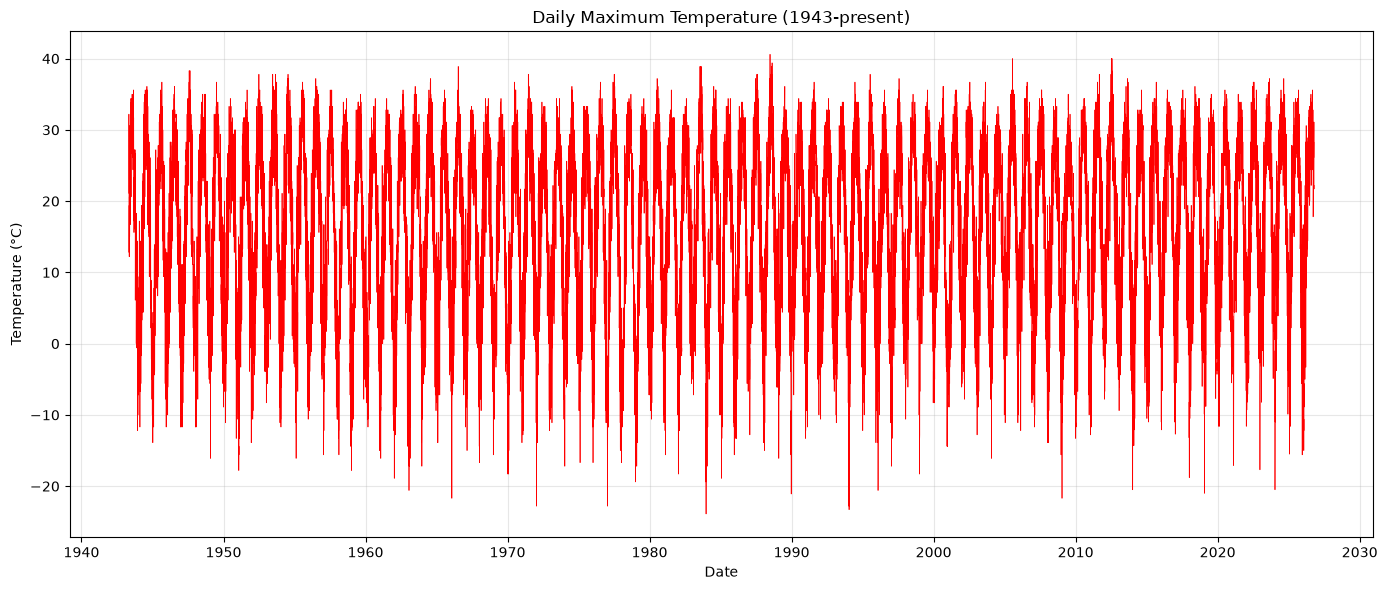

In [46]:
plt.figure(figsize=(14, 6))
plt.plot(df_clean["DATE"], df_clean["TMAX_C"], color="red", linewidth=0.5)
plt.title("Daily Maximum Temperature (1943-present)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

==== 检查1：TMAX整体统计 ====
平均最高温： 16.35 ℃
最高温标准差： 12.03 ℃
历史最高： 40.6 ℃
历史最低： -23.9 ℃

==== 检查2：历史最热/最冷的5天 ====
最热5天：
            DATE  TMAX_C
16487 1988-06-25    40.6
22725 2005-07-24    40.0
25265 2012-07-07    40.0
25281 2012-07-23    40.0
16540 1988-08-17    39.4
最冷5天：
            DATE  TMAX_C
14842 1983-12-24   -23.9
18520 1994-01-18   -23.3
10481 1972-01-15   -22.8
12309 1977-01-16   -22.8
18517 1994-01-15   -22.8


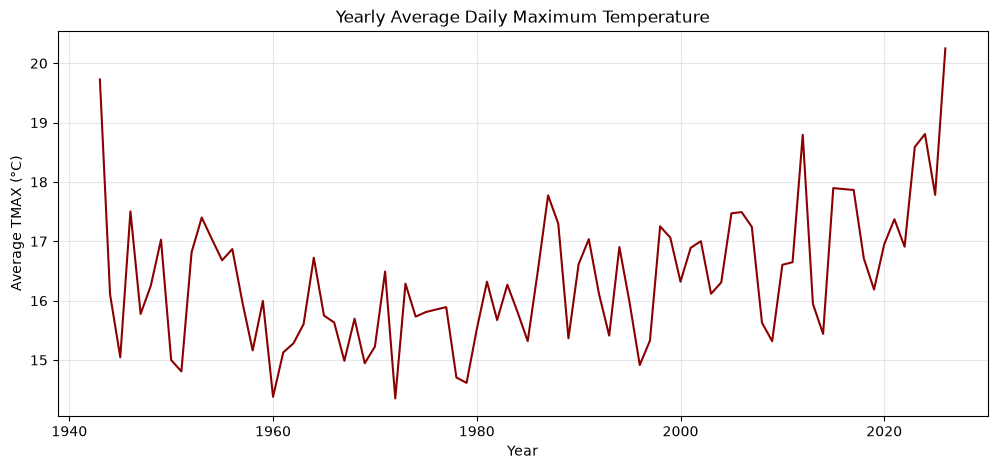

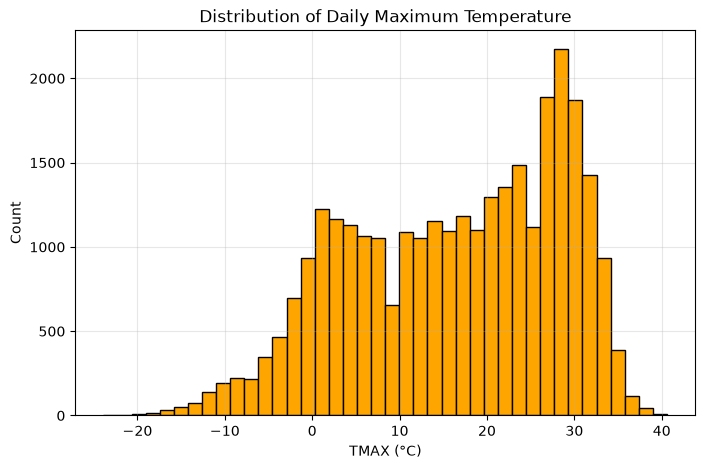


==== 检查5：降水统计 ====
年平均降水量： 915.6 mm
有降水的天数占比： 31.4 %
单日最大降水： 131.8 mm


In [47]:
# 检查1：整体平均值、标准差、最大最小值
print("==== 检查1：TMAX整体统计 ====")
print("平均最高温：", round(df_clean["TMAX_C"].mean(), 2), "℃")
print("最高温标准差：", round(df_clean["TMAX_C"].std(), 2), "℃")
print("历史最高：", df_clean["TMAX_C"].max(), "℃")
print("历史最低：", df_clean["TMAX_C"].min(), "℃")
# 检查2：最热和最冷的是哪几天
print("\n==== 检查2：历史最热/最冷的5天 ====")
print("最热5天：")
print(df_clean.nlargest(5, "TMAX_C")[["DATE", "TMAX_C"]])
print("最冷5天：")
print(df_clean.nsmallest(5, "TMAX_C")[["DATE", "TMAX_C"]])
# 检查3：每年平均最高温，看长期趋势
df_clean["year"] = df_clean["DATE"].dt.year
yearly_avg = df_clean.groupby("year")["TMAX_C"].mean()
plt.figure(figsize=(12, 5))
yearly_avg.plot(color="darkred")
plt.title("Yearly Average Daily Maximum Temperature")
plt.xlabel("Year")
plt.ylabel("Average TMAX (°C)")
plt.grid(alpha=0.3)
plt.show()
# 检查4：最高温的分布直方图
plt.figure(figsize=(8, 5))
plt.hist(df_clean["TMAX_C"], bins=40, color="orange", edgecolor="black")
plt.title("Distribution of Daily Maximum Temperature")
plt.xlabel("TMAX (°C)")
plt.ylabel("Count")
plt.grid(alpha=0.3)
plt.show()
# 检查5：降水统计
print("\n==== 检查5：降水统计 ====")
print("年平均降水量：", round(df_clean.groupby("year")["PRCP_mm"].sum().mean(), 1), "mm")
print("有降水的天数占比：", round((df_clean["PRCP_mm"] > 0).mean() * 100, 1), "%")
print("单日最大降水：", df_clean["PRCP_mm"].max(), "mm")
